In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import make_column_selector, ColumnTransformer
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler


In [ ]:

hr=pd.read_csv("D:\Machine Learning\Datasets\HR_comma_sep.csv")
X , y = hr.drop('left',axis=1) , hr['left']
ohe = OneHotEncoder(drop='first', sparse_output=False).set_output(transform="pandas")
col_transformer = ColumnTransformer([("OHE", ohe, make_column_selector(dtype_include=object))], 
                                    remainder='passthrough', 
                                    verbose_feature_names_out=False)
col_transformer = col_transformer.set_output(transform="pandas")
X = col_transformer.fit_transform(X)
X_train , X_test , y_train , y_test = train_test_split(X,y,test_size=0.3,random_state=25,stratify=y)
scl_x = MinMaxScaler()
X_train_scaled = scl_x.fit_transform(X_train)
X_test_scaled = scl_x.transform(X_test)

#### Using Keras API

In [54]:
initializer = tf.keras.initializers.GlorotUniform(seed= 25)
tf.random.set_seed(seed=25)
model = tf.keras.Sequential([tf.keras.Input(shape=(X_train_scaled.shape[1],)),
                            tf.keras.layers.Dense(10,activation='relu', kernel_initializer=initializer),
                            tf.keras.layers.Dense(5,activation='relu', kernel_initializer=initializer),
                            tf.keras.layers.Dense(1,activation='sigmoid', kernel_initializer=initializer)]) # first parameter → no. layers
model.compile(optimizer= tf.keras.optimizers.Adam(learning_rate=0.1),
              loss=tf.keras.losses.BinaryCrossentropy())
history = model.fit(X_train_scaled, y_train, validation_data=(X_test_scaled, y_test), epochs= 50)

Epoch 1/50
328/328 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4158 - val_loss: 0.3553
Epoch 2/50
328/328 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3582 - val_loss: 0.3087
Epoch 3/50
328/328 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3654 - val_loss: 0.3674
Epoch 4/50
328/328 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3609 - val_loss: 0.3361
Epoch 5/50
328/328 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3424 - val_loss: 0.3274
Epoch 6/50
328/328 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3162 - val_loss: 0.4464
Epoch 7/50
328/328 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2863 - val_loss: 0.2791
Epoch 8/50
328/328 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2727 - val_loss: 0.2734
Epoch 9/50
328/328 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2768 - val_loss: 0.2679
Epoch 10/50
328/328 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2678 - val_loss: 0.2937
Epoch 11/50
328/328 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2661 - val_loss: 0.2766
Epoch 12/50
328/328 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

In [55]:
initializer = tf.keras.initializers.GlorotUniform(seed= 25)
tf.random.set_seed(seed=25)
model = tf.keras.Sequential([tf.keras.Input(shape=(X_train_scaled.shape[1],)),
                            tf.keras.layers.Dense(14,activation='relu', kernel_initializer=initializer),
                            tf.keras.layers.Dense(9,activation='relu', kernel_initializer=initializer),
                            tf.keras.layers.Dense(4,activation='relu', kernel_initializer=initializer),
                            tf.keras.layers.Dense(1,activation='sigmoid', kernel_initializer=initializer)]) # first parameter → no. layers
model.compile(optimizer= tf.keras.optimizers.Adam(learning_rate=0.001),
              loss=tf.keras.losses.BinaryCrossentropy())
history = model.fit(X_train_scaled, y_train, validation_data=(X_test_scaled, y_test), epochs= 50)

Epoch 1/50
328/328 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.6018 - val_loss: 0.5141
Epoch 2/50
328/328 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4734 - val_loss: 0.4213
Epoch 3/50
328/328 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3839 - val_loss: 0.3419
Epoch 4/50
328/328 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3201 - val_loss: 0.2907
Epoch 5/50
328/328 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2779 - val_loss: 0.2599
Epoch 6/50
328/328 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2527 - val_loss: 0.2410
Epoch 7/50
328/328 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2358 - val_loss: 0.2278
Epoch 8/50
328/328 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2234 - val_loss: 0.2173
Epoch 9/50
328/328 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2132 - val_loss: 0.2094
Epoch 10/50
328/328 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2046 - val_loss: 0.2029
Epoch 11/50
328/328 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.1977 - val_loss: 0.1977
Epoch 12/50
328/328 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

In [ ]:
from sklearn.metrics import log_loss
y_pred_prob = model.predict(X_test_scaled)
print(log_loss(y_test, y_pred_prob))
      

141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
0.14983094971409752


In [57]:
from sklearn.metrics import accuracy_score
y_pred = np.where(y_pred_prob >= 0.5,1,0)
print(accuracy_score(y_test, y_pred))
#accuracy_score → 0.91 on learning_rate = 0.1 & Layers- 10→5→1
# accuracy_score → 0.95 on learning_rate = 0.001 & Layers- 14→9→4→1

0.9542120471215826


#### L1 Regularizer

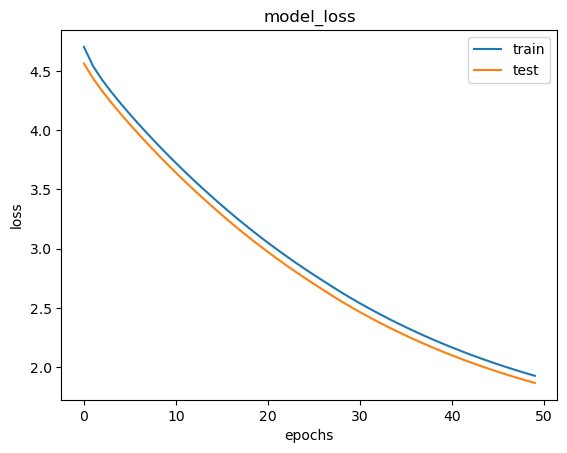

In [97]:
import matplotlib.pyplot as plt
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model_loss')
plt.ylabel('loss')
plt.xlabel('epochs')
plt.legend(['train', 'test'], loc= 'upper right')
plt.show()